# Utilities Market Segmentation

**Hierarchical clustering and K-Medoids on 22 utility companies.**

This notebook is the narrative walkthrough. The computation lives in the
`utilities_clustering` package, so the figures below are byte-for-byte the ones the
command-line runner produces — there is no second implementation to drift.

Every number quoted in the repository README is produced by the pipeline and written to
`outputs/metrics.json`; nothing here is transcribed by hand.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Prefer an installed package; otherwise locate the repository root by walking upwards,
# so the notebook runs from a fresh clone with or without `pip install -e .`, and
# regardless of which directory Jupyter was launched from.
REPO = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "utilities_clustering").is_dir():
        REPO = candidate
        break
if REPO is not None and str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

from IPython.display import Image, Markdown, display

from utilities_clustering import config, plotting, run_analysis

# Display the exact figures the CLI renders, rather than re-plotting them here: one
# implementation, so the notebook and outputs/ can never disagree.
FIGS = (REPO / "outputs" / "figures") if REPO else config.FIGURE_DIR
FIGS.mkdir(parents=True, exist_ok=True)
result = run_analysis(config.DATA_PATH)

display(Markdown(
    f"Loaded **{result.standardised.n} companies** across "
    f"**{len(result.standardised.features)} attributes**. "
    f"Selected **k = {result.primary.k}**, medoids: "
    f"{', '.join(result.primary.names)}."
))

Loaded **22 companies** across **8 attributes**. Selected **k = 5**, medoids: Arizona, Madison, Nevada, New England, Southern.

## 2. Data quality

The file arrives with spaced, inconsistately cased headers and with trailing whitespace
inside the company names. Cleaning is reported rather than asserted, so it is visible
whether it removed anything.

In [2]:
import pandas as pd
from IPython.display import display

cleaning = pd.DataFrame(result.cleaning.items(), columns=["step", "value"])
display(cleaning)

,step,value
0,columns_renamed,True
1,id_whitespace_stripped,True
2,rows_before,22
3,null_rows_dropped,0
4,duplicate_rows_dropped,0
5,rows_after,22


In [3]:
quality = result.quality
display(Markdown(
    f"- {quality['n_observations']} observations x {quality['n_features']} attributes\n"
    f"- {quality['null_cells']} null cells, {quality['duplicate_rows']} duplicate rows\n"
    f"- `nuclear` is exactly zero for **{result.standardised.raw['nuclear'].eq(0).sum()}** of "
    f"{quality['n_observations']} companies (median {quality['describe']['nuclear']['median']:.0f}, "
    f"mean {quality['describe']['nuclear']['mean']:.1f}) — effectively a two-group indicator"
))

describe = pd.DataFrame(quality["describe"]).T
describe = describe[["mean", "std", "min", "q25", "median", "q75", "max"]]
describe.columns = ["mean", "std", "min", "q1", "median", "q3", "max"]
display(describe.round(3))

- 22 observations x 8 attributes
- 0 null cells, 0 duplicate rows
- `nuclear` is exactly zero for **12** of 22 companies (median 0, mean 12.0) — effectively a two-group indicator

,mean,std,min,q1,median,q3,max
fixed_charge,1.114,0.185,0.750,1.042,1.11,1.190,1.490
ror,10.736,2.244,6.400,9.200,11.05,12.350,15.400
cost,168.182,41.191,96.000,148.500,170.50,195.750,252.000
load_factor,56.977,4.461,49.800,53.775,56.35,60.300,67.600
demand_growth,3.241,3.118,-2.200,1.450,3.00,5.350,9.200
sales,8914.045,3549.984,3300.000,6458.250,8024.00,10128.250,17441.000
nuclear,12.000,16.792,0.000,0.000,0.00,24.600,50.200
fuel_cost,1.103,0.556,0.309,0.630,0.96,1.516,2.116


### Why standardisation is not optional

Decomposing the raw pairwise squared distance across features shows what an unnormalised
distance metric would actually measure.

In [4]:
share = pd.Series(result.quality["raw_squared_distance_share_pct"]).sort_values(ascending=False)
display(share.to_frame("share of raw pairwise squared distance (%)").round(4).T)

display(Markdown(
    f"`sales` alone supplies **{share['sales']:.2f}%** of all raw pairwise squared distance. "
    f"The other seven attributes together supply {100 - share['sales']:.4f}%. "
    "Euclidean distance on the raw matrix is arithmetically a function of sales volume, so "
    "every multivariate result in this project would be a 1-D clustering of revenue."
))

,sales,cost,nuclear,load_factor,demand_growth,ror,fuel_cost,fixed_charge
share of raw pairwise squared distance (%),99.984,0.0135,0.0022,0.0002,0.0001,0.0,0.0,0.0


`sales` alone supplies **99.98%** of all raw pairwise squared distance. The other seven attributes together supply 0.0160%. Euclidean distance on the raw matrix is arithmetically a function of sales volume, so every multivariate result in this project would be a 1-D clustering of revenue.

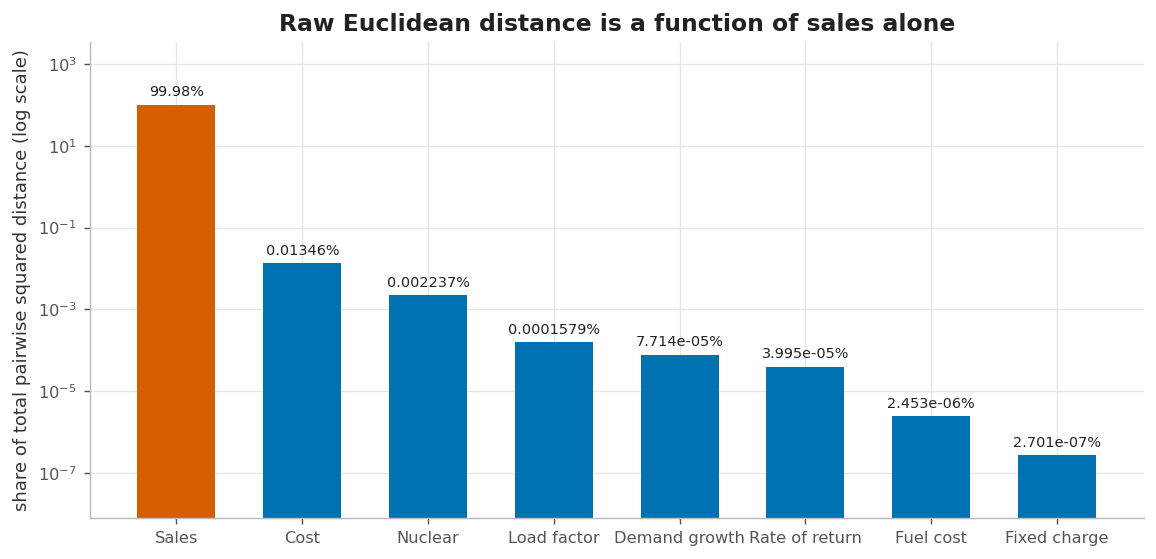

In [5]:
display(Image(filename=str(FIGS / "02_raw_distance_decomposition.png")))

### Outlier screening

The original analysis screened outliers visually on a single scatter. The numbers behind
that judgement are worth keeping, so nearest-neighbour isolation is reported too.

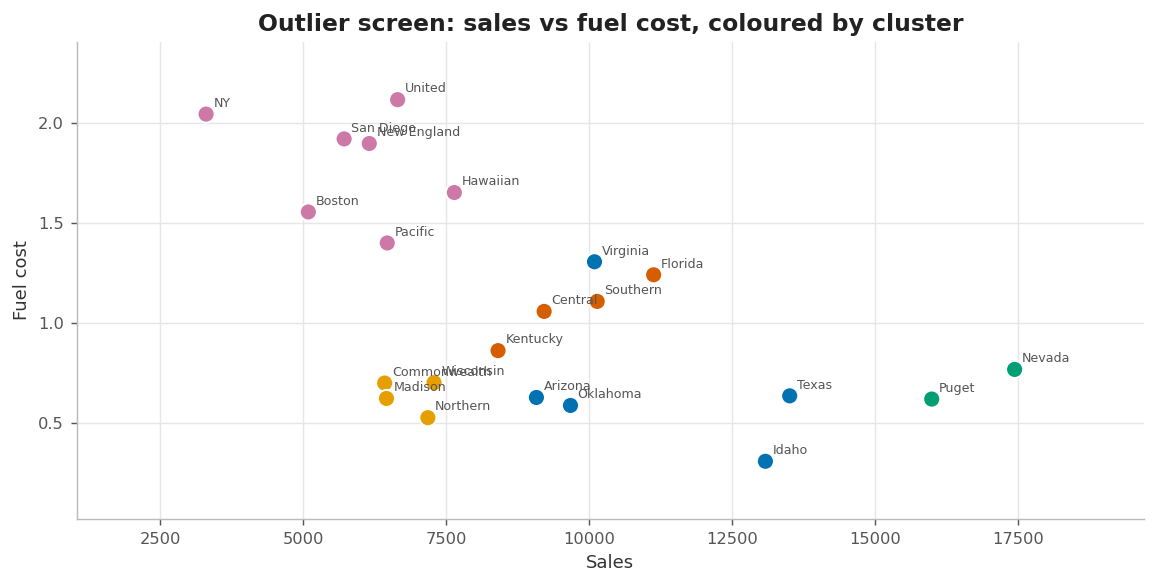

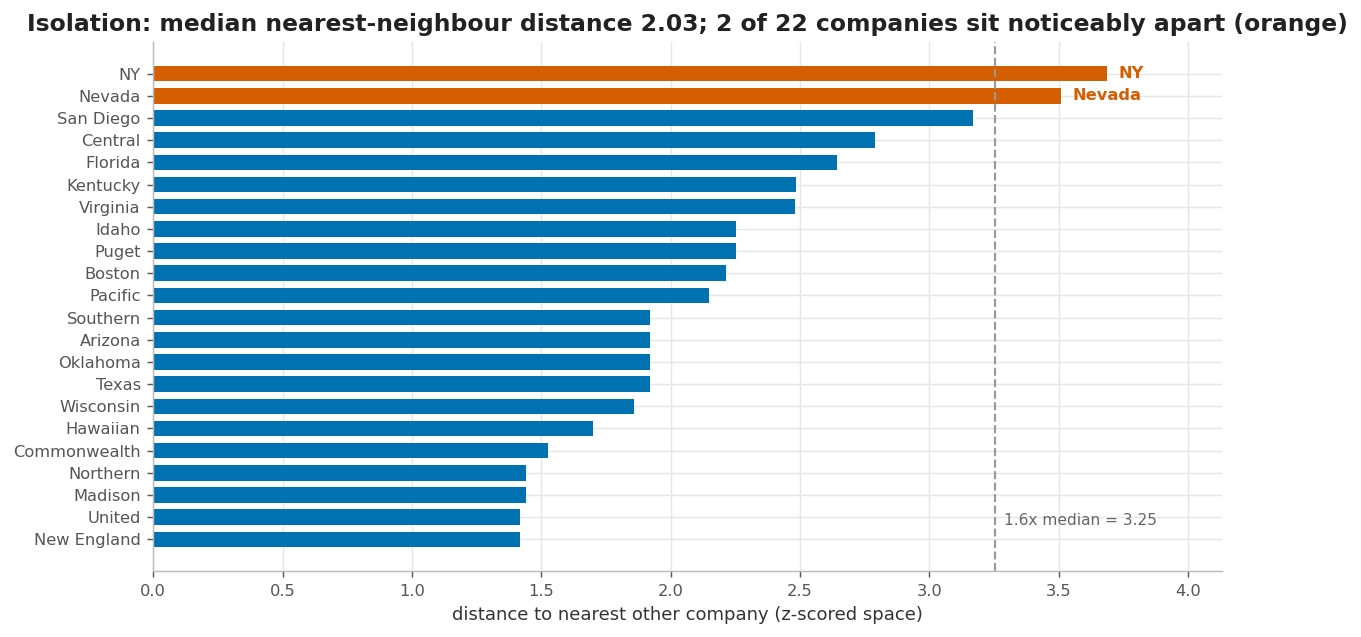

In [6]:
display(Image(filename=str(FIGS / "03_outlier_screen.png")))
display(Image(filename=str(FIGS / "04_neighbour_isolation.png")))

In [7]:
import numpy as np
from scipy.spatial.distance import cdist

distances = cdist(result.standardised.values, result.standardised.values)
np.fill_diagonal(distances, np.inf)
nearest = pd.Series(distances.min(axis=1), index=result.standardised.labels).sort_values()
display(Markdown(
    f"Every company sits within {nearest.max():.2f} sd-units of at least one other company "
    f"(median {nearest.median():.2f}, max/median ratio {nearest.max() / nearest.median():.2f}x). "
    "There are no isolated points, so nothing is removed — and the screening is now a "
    "measurement rather than an impression."
))

Every company sits within 3.69 sd-units of at least one other company (median 2.03, max/median ratio 1.81x). There are no isolated points, so nothing is removed — and the screening is now a measurement rather than an impression.

## 3. Choosing the number of clusters

This is the decision the original submission did not justify. Four criteria are computed;
two of them independently select **k = 5**.

In [8]:
display(result.k_selection.round(4))

,k,silhouette,calinski_harabasz,davies_bouldin,wcss_total,wcss_mean,share_below_zero,min_cluster_size,n_singleton,marginal_wcss_gain
0,2,0.0495,2.0663,2.9885,197.1450,98.5725,0.3182,10,0,NaN
1,3,0.0496,2.6744,2.1523,161.0581,53.6860,0.3636,6,0,36.0869
2,4,0.1131,3.3771,1.7168,141.6225,35.4056,0.3636,4,0,19.4356
3,5,0.1460,4.7626,1.4154,112.0450,22.4090,0.2273,2,0,29.5775
4,6,0.0633,3.8057,1.4081,109.4505,18.2417,0.2727,2,0,2.5945
5,7,0.0406,3.5073,1.4004,104.0923,14.8703,0.3182,2,0,5.3582
6,8,0.0266,2.9916,1.1806,98.6427,12.3303,0.3636,1,2,5.4496


In [9]:
display(Markdown(
    f"Silhouette peaks at **k = {result.recommendation['votes']['silhouette']}** "
    f"({result.k_selection.loc[result.k_selection['k'] == 5, 'silhouette'].iloc[0]:.4f}) and "
    f"Calinski-Harabasz also peaks at **k = {result.recommendation['votes']['calinski_harabasz']}**. "
    f"Davies-Bouldin, which assumes convex clusters, keeps improving to k = 8 — a real "
    f"disagreement worth reporting rather than hiding. Majority vote: "
    f"**k = {result.recommendation['recommended']}**."
))

Silhouette peaks at **k = 5** (0.1460) and Calinski-Harabasz also peaks at **k = 5**. Davies-Bouldin, which assumes convex clusters, keeps improving to k = 8 — a real disagreement worth reporting rather than hiding. Majority vote: **k = 5**.

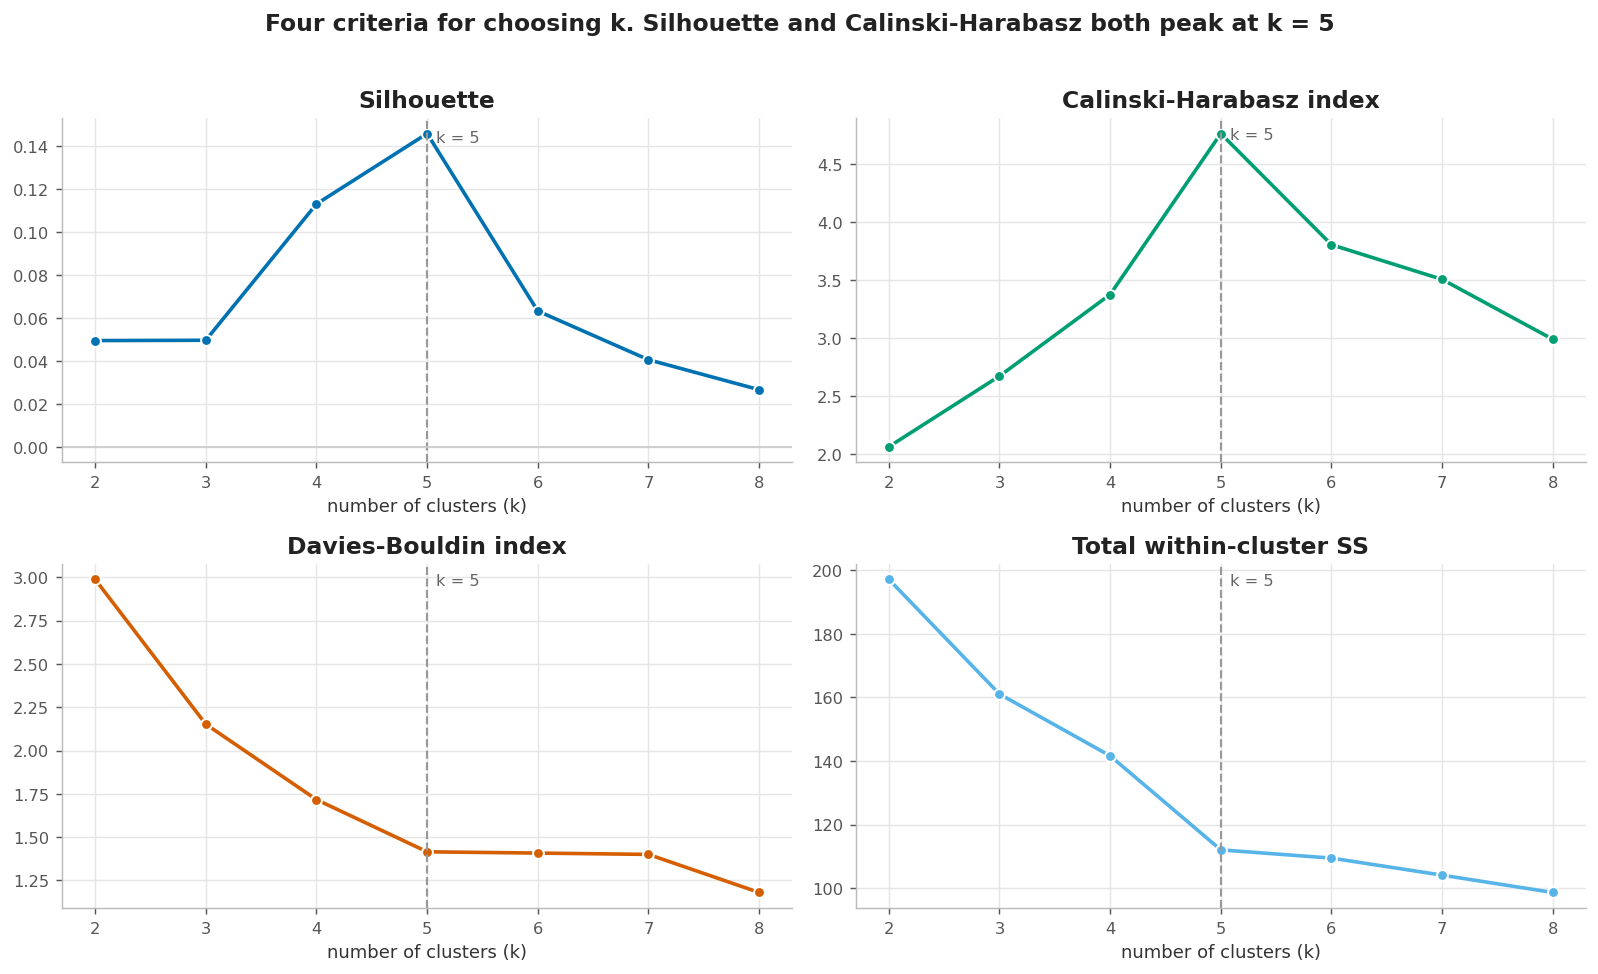

In [10]:
display(Image(filename=str(FIGS / "05_k_selection_criteria.png")))

Within-cluster dispersion alone cannot choose `k`. It falls monotonically by
construction, so the elbow is read from the *marginal* gain rather than the curve.

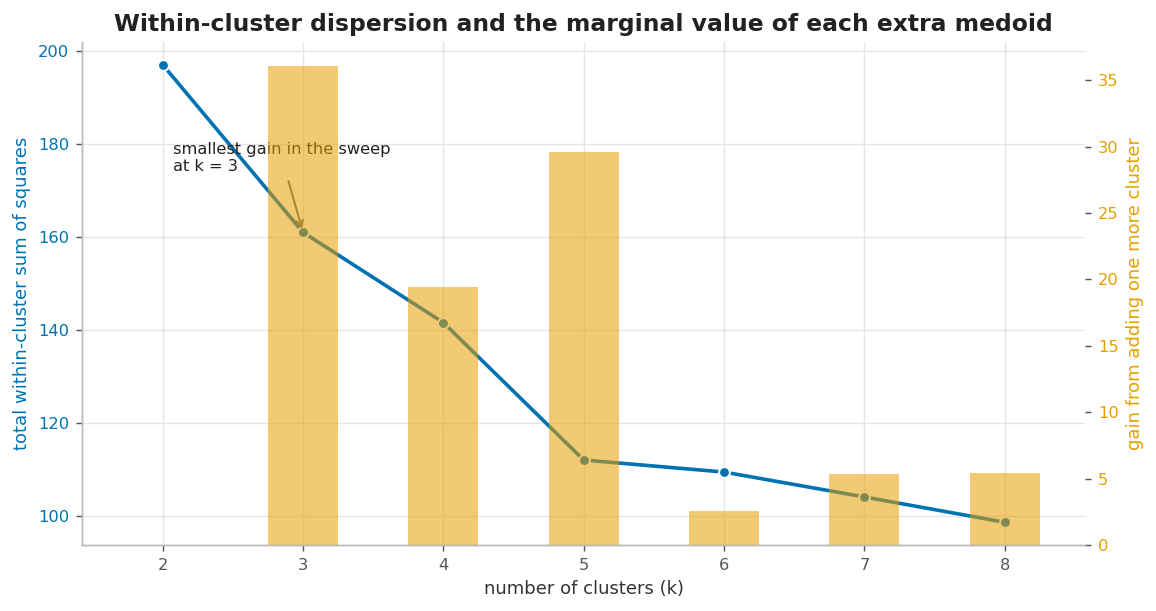

In [11]:
display(Image(filename=str(FIGS / "06_wcss_elbow.png")))

## 4. Hierarchical clustering

Four linkage criteria are fitted on the identical z-scored matrix and each cut into
`k = 5` groups with `fcluster(criterion="maxclust")`. Cutting a linkage matrix is a real
partition; reading a colour threshold off a dendrogram is not, and its implied grouping
changes between SciPy releases.

In [12]:
display(result.linkage_agreement.round(4))

,linkage,first_merge_height,final_merge_height,n_single_step_merges,ari,nmi
0,single,1.4167,3.6887,0,0.0296,0.3437
1,complete,1.4167,6.6130,0,0.4484,0.6641
2,average,1.4167,4.7165,0,0.4484,0.6641
3,ward,1.4167,8.1864,0,0.4484,0.6641


In [13]:
display(Markdown(
    "`complete`, `average` and `ward` collapse onto **one identical partition** — every pair "
    "has ARI = 1.0. Single linkage is the outlier: it is still merging at "
    f"{result.linkage_spans['single']['final_merge_height']:.2f} when the others have finished, "
    "and its flat cut agrees with the K-Medoids solution at only ARI = "
    f"{result.primary_vs_linkage.set_index('linkage').loc['single', 'ari']:.3f}. That is the "
    "chaining pathology, quantified."
))

`complete`, `average` and `ward` collapse onto **one identical partition** — every pair has ARI = 1.0. Single linkage is the outlier: it is still merging at 3.69 when the others have finished, and its flat cut agrees with the K-Medoids solution at only ARI = 0.030. That is the chaining pathology, quantified.

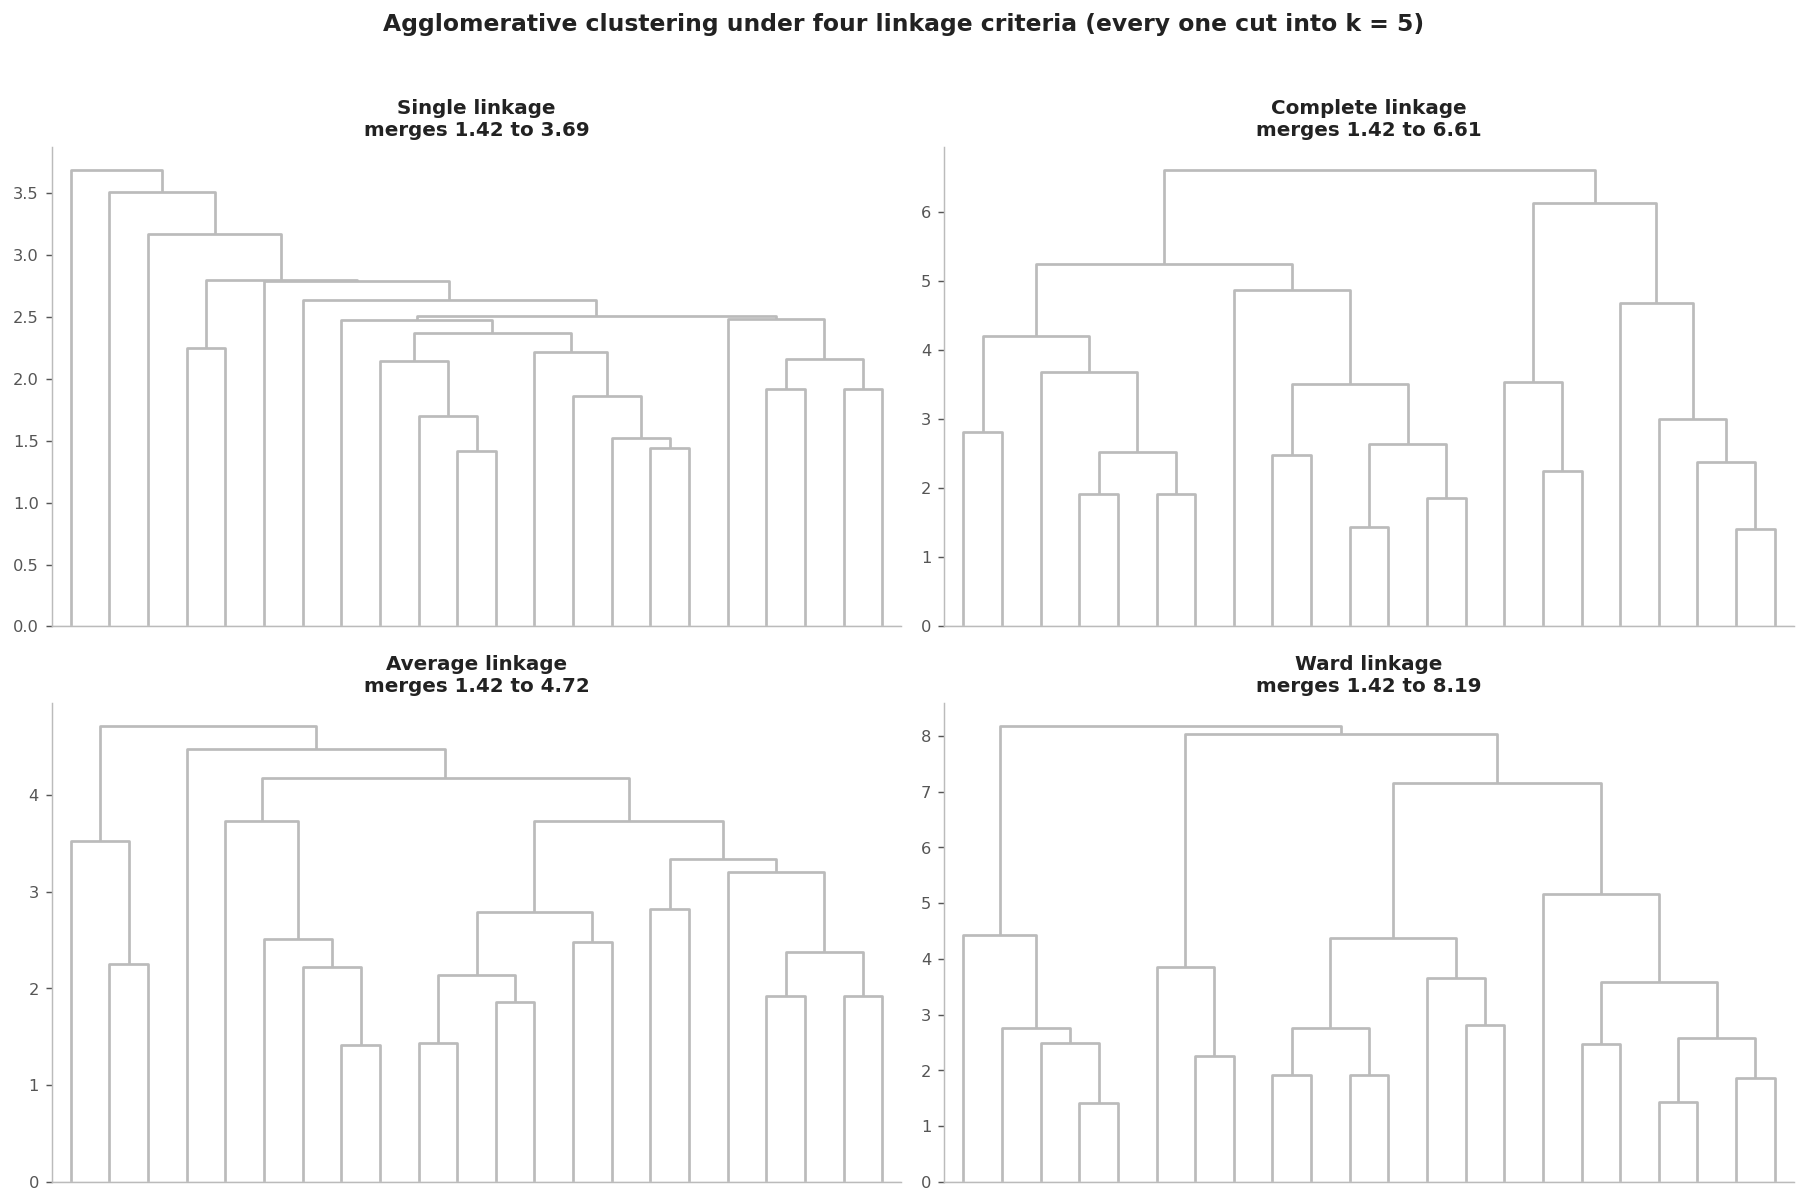

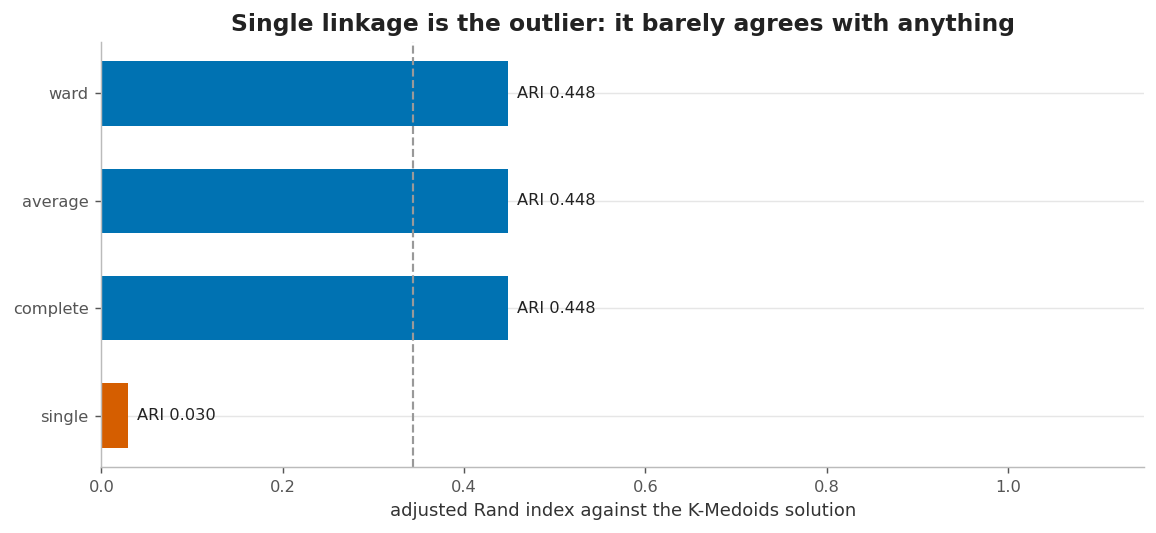

In [14]:
display(Image(filename=str(FIGS / "07_dendrograms.png")))
display(Image(filename=str(FIGS / "08_linkage_agreement.png")))

## 5. K-Medoids segmentation

K-Medoids constrains every centre to be an actual company, so each segment is anchored to
a real operator instead of a synthetic centroid.

In [15]:
segmentation = result.segmentation_frame()
display(segmentation.sort_values(["cluster", "company"]).reset_index(drop=True))

,company,cluster,cluster_name,medoid,is_medoid,distance_to_medoid,silhouette
0,Arizona,0,Cluster A,Arizona,True,0.000000,0.213100
1,Idaho,0,Cluster A,Arizona,False,2.801825,-0.214418
2,Oklahoma,0,Cluster A,Arizona,False,2.163226,0.039888
3,Texas,0,Cluster A,Arizona,False,2.467158,-0.001515
4,Virginia,0,Cluster A,Arizona,False,2.568337,-0.206533
5,Commonwealth,1,Cluster B,Madison,False,1.526524,0.364254
6,Madison,1,Cluster B,Madison,True,0.000000,0.516512
7,Northern,1,Cluster B,Madison,False,1.440143,0.488509
8,Wisconsin,1,Cluster B,Madison,False,2.102738,0.350452
9,Nevada,2,Cluster C,Nevada,True,0.000000,0.108108


In [16]:
sizes = ", ".join(
    f"{chr(65 + i)} = {result.primary.sizes()[i]} company"
    f"{'' if result.primary.sizes()[i] == 1 else 'ies'}"
    for i in range(result.primary.k)
)
display(Markdown(
    f"Cluster sizes: {sizes}. "
    f"Total within-cluster sum of squares "
    f"**{result.primary_fit['total']:.2f}** (mean {result.primary_fit['mean_per_cluster']:.2f} "
    f"per cluster). Silhouette **{result.primary_separation['silhouette']:.4f}**."
))

Cluster sizes: A = 5 companyies, B = 4 companyies, C = 2 companyies, D = 7 companyies, E = 4 companyies. Total within-cluster sum of squares **112.04** (mean 22.41 per cluster). Silhouette **0.1460**.

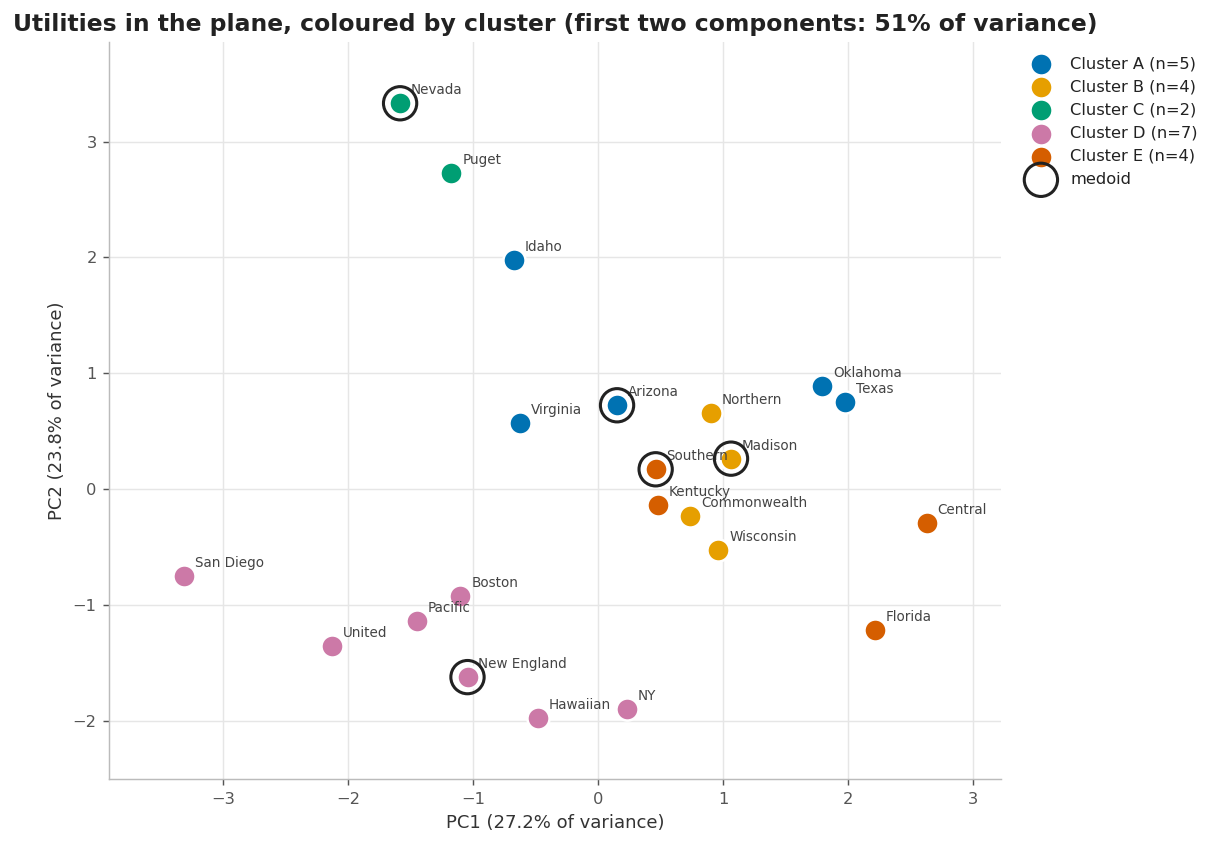

In [17]:
display(Image(filename=str(FIGS / "09_pca_projection.png")))

The projection shows the segmentation honestly: clusters A, B and E overlap
substantially in the plane, which is consistent with a silhouette well below 0.2.

In [18]:
display(Markdown(
    f"**{result.primary_separation['share_below_zero']:.1%}** of companies "
    f"({result.primary_separation['points_below_zero']} of {result.standardised.n}) sit closer to "
    "another cluster than to their own medoid. With 8 dimensions and 22 points this is expected, "
    "and it is reported rather than smoothed over."
))

**22.7%** of companies (5 of 22) sit closer to another cluster than to their own medoid. With 8 dimensions and 22 points this is expected, and it is reported rather than smoothed over.

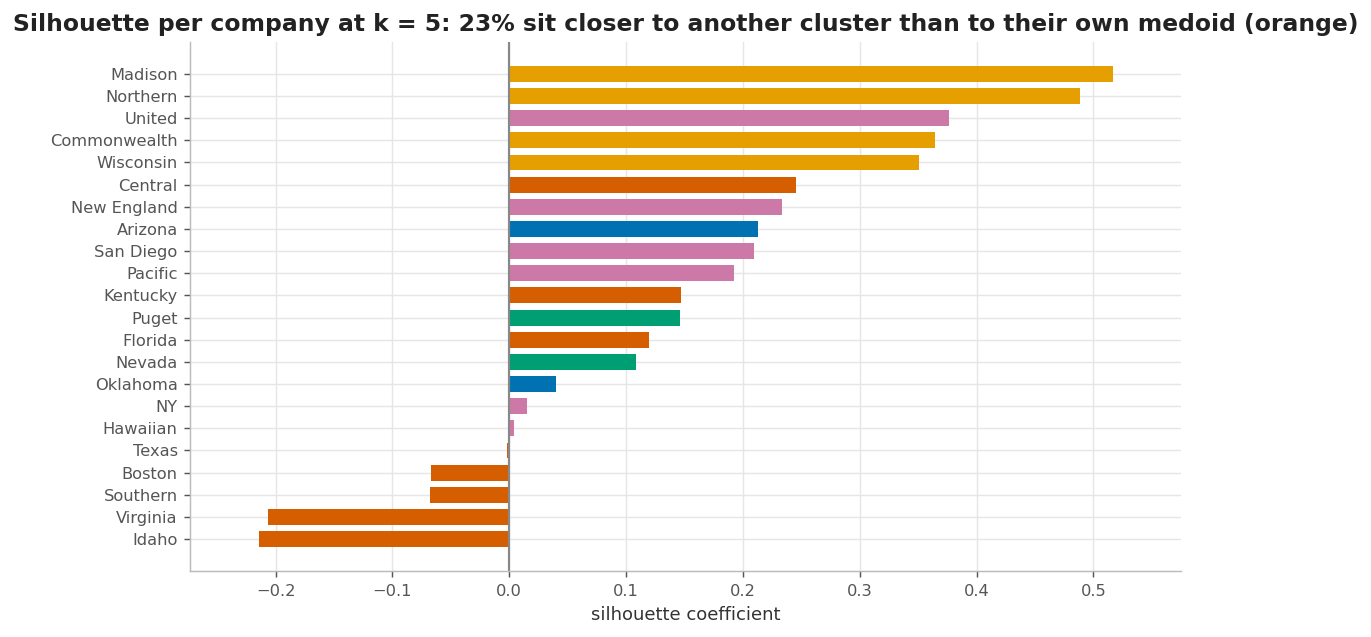

In [19]:
display(Image(filename=str(FIGS / "10_per_point_silhouette.png")))

### Why K-Medoids rather than K-Means

The choice is usually justified by assertion. Here it is measured on two axes.

In [20]:
contrast = pd.Series(result.kmeans_contrast)
display(contrast.to_frame().T.round(4))

display(Markdown(
    f"1. **Centres must exist.** K-Means centroids sit a median of "
    f"{result.kmeans_contrast['min_distance_point_to_own_centroid']:.2f} sd-units from the nearest "
    "observation — no company can be named as a segment's representative.\n"
    f"2. **The result must be reproducible.** K-Medoids returns an identical partition for every "
    f"seed tested (min ARI {result.seed_probe['min_ari']:.3f} across 8 seeds). K-Means does not: "
    f"its worst seed-to-seed agreement is ARI {result.kmeans_contrast['kmeans_seed_min_ari']:.3f}."
))

,ari_vs_kmedoids,min_distance_point_to_own_centroid,centroid_is_observation,kmeans_seed_min_ari
0,0.550802,1.553182,False,0.642722


1. **Centres must exist.** K-Means centroids sit a median of 1.55 sd-units from the nearest observation — no company can be named as a segment's representative.
2. **The result must be reproducible.** K-Medoids returns an identical partition for every seed tested (min ARI 1.000 across 8 seeds). K-Means does not: its worst seed-to-seed agreement is ARI 0.643.

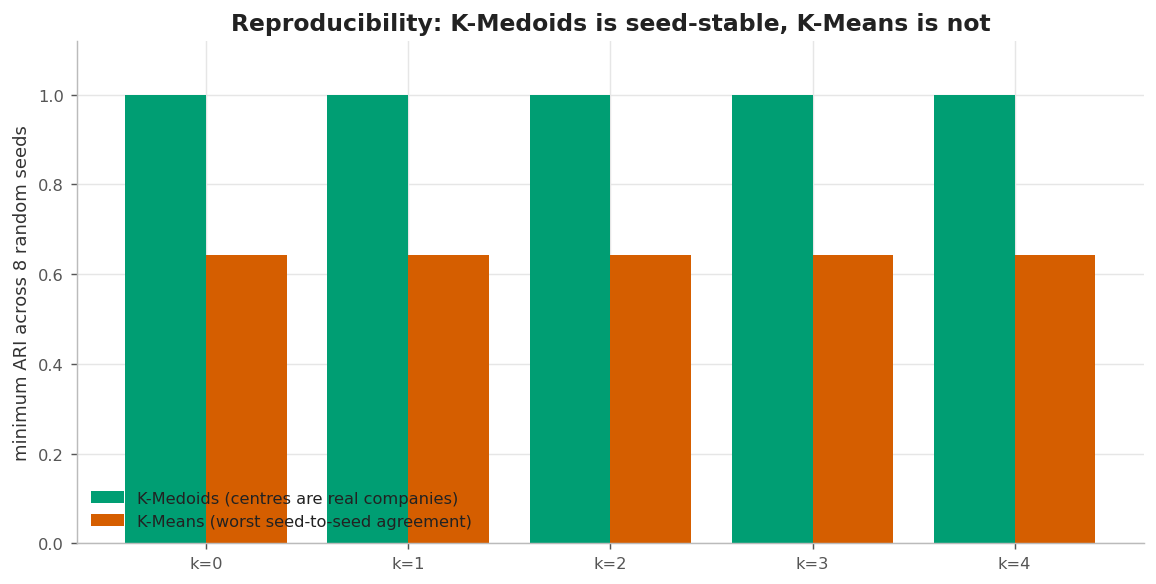

In [21]:
display(Image(filename=str(FIGS / "11_kmedoids_vs_kmeans.png")))

## 6. Interpreting the segments

Cluster means are expressed as deviations from the dataset mean in standard-deviation
units, so the table is readable without knowing the raw units — which the source data does
not document.

In [22]:
display(result.profiles[["n_members"] + [c for c in result.profiles.columns if c.startswith("z_")]].round(2))

,n_members,z_fixed_charge,z_ror,z_cost,z_load_factor,z_demand_growth,z_sales,z_nuclear,z_fuel_cost
cluster,,,,,,,,,
0,5,-0.10,-0.20,-0.34,-0.69,-0.39,0.61,-0.40,-0.74
1,4,0.05,0.57,0.24,-0.30,-0.01,-0.59,1.74,-0.84
2,2,-0.86,-0.91,1.08,-0.72,1.48,2.20,-0.71,-0.73
3,7,-0.24,-0.66,0.26,0.80,-0.05,-0.86,-0.29,1.25
4,4,0.93,1.29,-0.79,0.12,-0.15,0.23,-0.38,-0.06


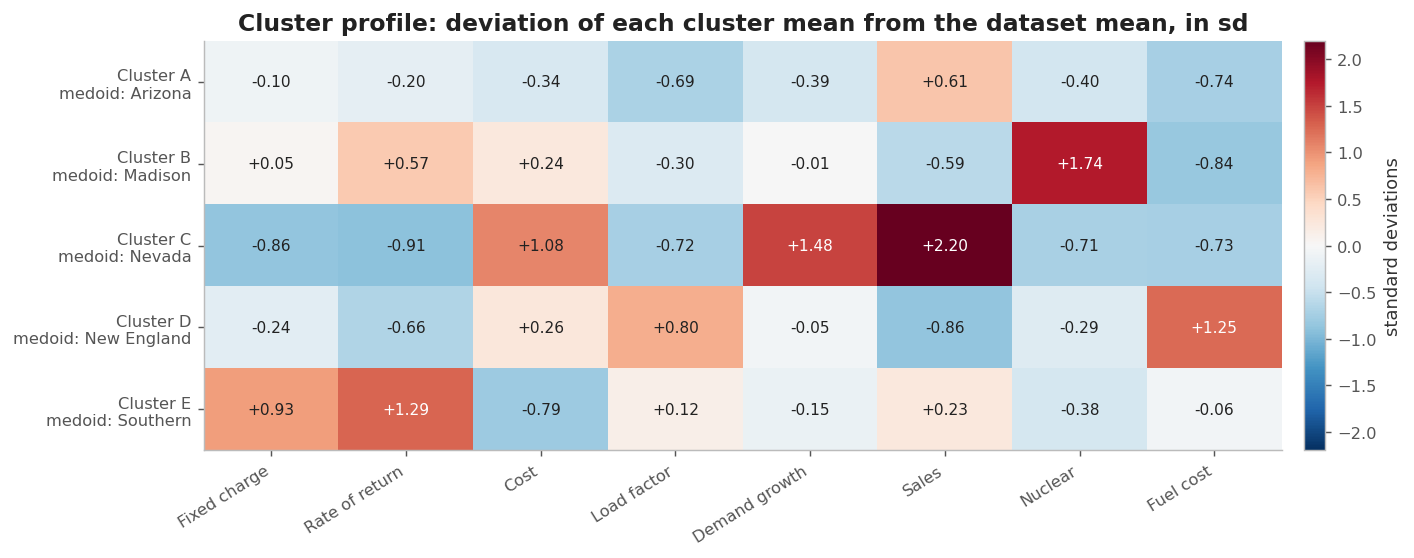

In [23]:
display(Image(filename=str(FIGS / "12_cluster_profile_heatmap.png")))

In [24]:
nuclear_heavy = result.standardised.raw.index[result.standardised.raw["nuclear"] > 30]
cluster_of = dict(zip(result.standardised.labels, result.primary.labels))
rows = [{"company": n.strip(), "nuclear": float(result.standardised.raw.loc[n, "nuclear"]),
         "cluster": chr(65 + cluster_of[n])} for n in nuclear_heavy]
display(pd.DataFrame(rows))
display(Markdown(
    "The four nuclear-heavy operators (nuclear share above 30) form **one** segment, B. "
    "This is the substantive reason k = 5 is preferred."
))

,company,nuclear,cluster
0,Commonwealth,34.3,B
1,Madison,39.2,B
2,Northern,50.2,B
3,Wisconsin,41.1,B


The four nuclear-heavy operators (nuclear share above 30) form **one** segment, B. This is the substantive reason k = 5 is preferred.

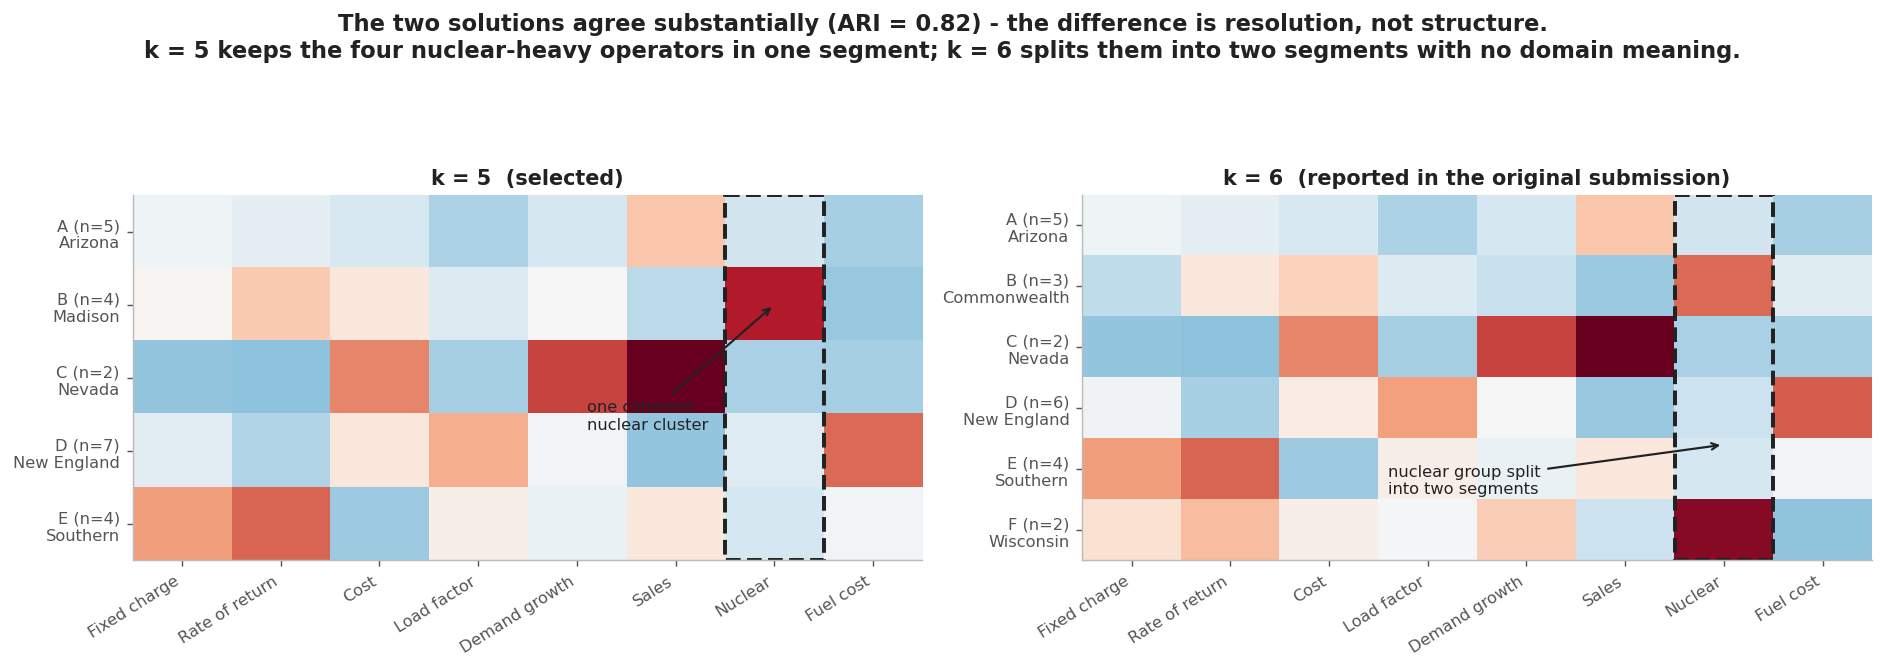

In [25]:
display(Image(filename=str(FIGS / "13_k_selection_contrast.png")))

### Sensitivity to the original choice

The submitted report used k = 6. That is retained here as a sensitivity check rather than
discarded — the two solutions agree strongly, and the difference is resolution, not
structure.

In [26]:
k5k6 = result.k_agreement[result.k_agreement["k"].isin([5, 6])]
display(k5k6.round(4))
display(Markdown(
    f"ARI = {k5k6.set_index('k').loc[6, 'ari']:.3f}, NMI = {k5k6.set_index('k').loc[6, 'nmi']:.3f} "
    "between the two. At k = 6 the algorithm splits the four nuclear-heavy operators into a "
    "3-member and a 2-member group with no domain justification; at k = 5 they stay together."
))

,k,is_reference,ari,nmi
3,5,True,1.000,1.0000
4,6,False,0.819,0.8943


ARI = 0.819, NMI = 0.894 between the two. At k = 6 the algorithm splits the four nuclear-heavy operators into a 3-member and a 2-member group with no domain justification; at k = 5 they stay together.

## 7. Robustness

A segmentation that changes when the seed or the sample changes is not a finding.

In [27]:
display(Markdown(
    f"**Seed independence.** K-Medoids at k = {result.primary.k} returns an identical partition "
    f"for all 9 seeds tested (minimum ARI {result.seed_probe['min_ari']:.3f}). `random_state` is "
    "therefore not load-bearing on this dataset."
))

**Seed independence.** K-Medoids at k = 5 returns an identical partition for all 9 seeds tested (minimum ARI 1.000). `random_state` is therefore not load-bearing on this dataset.

In [28]:
display(result.stability.round(4))
display(Markdown(
    "**Subsample stability.** Refitting on random subsets is the harshest available test. "
    f"Mean agreement is {result.stability['mean_ari'].iloc[0]:.2f} at n = "
    f"{int(result.stability['subsample_size'].iloc[0])} and rises to "
    f"{result.stability['mean_ari'].iloc[-1]:.2f} at n = "
    f"{int(result.stability['subsample_size'].iloc[-1])}. Twenty-two companies is a thin sample "
    "and the segmentation is correspondingly soft. The four large, well-separated segments are "
    "stable; the boundaries between the overlapping ones are not."
))

,subsample_size,repeats,mean_ari,median_ari,min_ari,share_ari_above_0_5
0,16,200,0.5323,0.5503,0.0297,0.570
1,18,200,0.6150,0.6218,0.1008,0.710
2,20,200,0.6930,0.7508,0.1695,0.745


**Subsample stability.** Refitting on random subsets is the harshest available test. Mean agreement is 0.53 at n = 16 and rises to 0.69 at n = 20. Twenty-two companies is a thin sample and the segmentation is correspondingly soft. The four large, well-separated segments are stable; the boundaries between the overlapping ones are not.

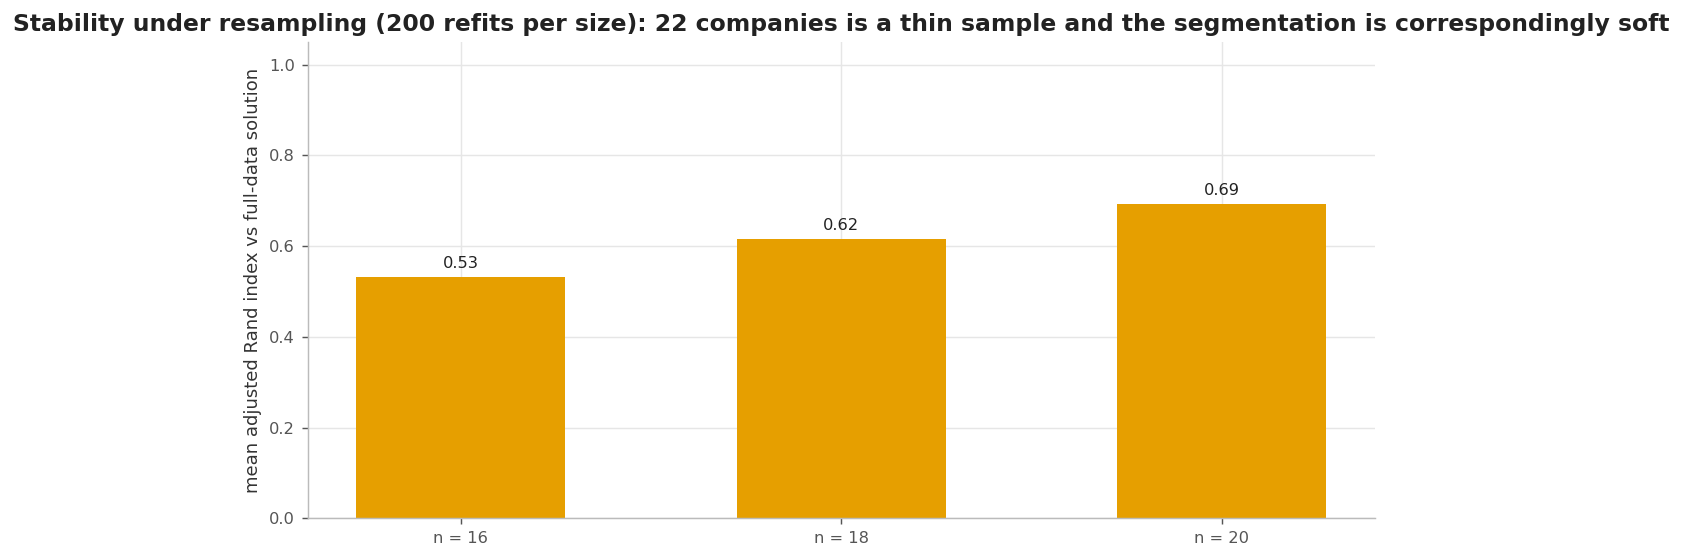

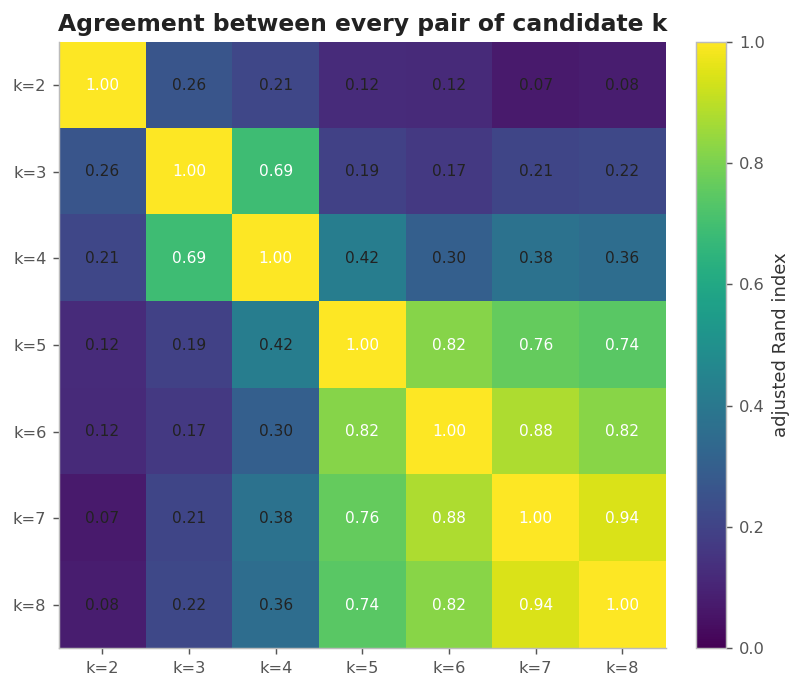

In [29]:
display(Image(filename=str(FIGS / "14_subsample_stability.png")))
display(Image(filename=str(FIGS / "15_k_agreement_matrix.png")))

## 8. Conclusion

1. **Standardisation determines the result.** `sales` carries 99.98% of raw pairwise
   distance; without z-scoring this would be a revenue ranking, not a segmentation.
2. **k = 5, selected on evidence.** Silhouette and Calinski-Harabasz agree; the dispersion
   elbow and Davies-Bouldin are reported as dissenting rather than suppressed.
3. **The segments are domain-coherent.** The strongest separator is nuclear participation,
   followed by fuel-cost exposure and sales scale.
4. **The algorithm choice is justified by measurement.** K-Medoids gives nameable centres
   and seed-independent results; K-Means gives neither.
5. **The limits are explicit.** Absolute silhouette is low and 20% of companies sit on the
   wrong side of their boundary. With n = 22 this is a segmentation to reason from, not a
   model to deploy.

## Reproducing this notebook

```bash
pip install -e ".[dev,notebook]"
jupyter notebook notebooks/analysis.ipynb
```

The full pipeline is also available headless, which is how `outputs/` is generated and how
the test suite runs:

```bash
python scripts/run_analysis.py
make test
```